In [59]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

#### Pre processing img data 

In [60]:
train_dir = "dataset/cifar-10-img/cifar-10-img/train"
test_dir = "dataset/cifar-10-img/cifar-10-img/test"

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
)

test_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
)

# here batch_size is the number of images in each batch
train_batch_size = 5000
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(32, 32),
    batch_size=train_batch_size,
    class_mode='categorical'
)
test_batch_size = 1000
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(32, 32),
    batch_size=test_batch_size,
    class_mode='categorical'
)

Found 40079 images belonging to 10 classes.
Found 9921 images belonging to 10 classes.


#### Selecting only first batch with 5000 images as train and test data

In [61]:
x_train, y_train =  train_generator[0]
x_test, y_test = test_generator[0]

print(len(x_train))
print(len(x_test))

5000
1000


#### a. Load in a pre-trained CNN model trained on a large dataset

In [62]:
# Load VGG16 without top layers
weights_path = "dataset/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5"
base_model = VGG16(weights=weights_path, include_top=False, input_shape=(32, 32, 3))

#### b. Freeze parameters (weights) in model’s lower convolutional layers

In [63]:
for layer in base_model.layers:
   layer.trainable = False

#### c. Add custom classifier with several layers of trainable parameters to model

In [64]:
x = Flatten()(base_model.output)
x = Dense(256, activation='relu')(x)
x = tf.keras.layers.Dropout(0.3)(x)
x = Dense(256, activation='relu')(x)
x = tf.keras.layers.Dropout(0.3)(x)
predictions = Dense(10, activation='softmax')(x)

# Create the model
model = Model(inputs=base_model.input, outputs=predictions)
# Compile the model
model.compile(optimizer="adam", loss='categorical_crossentropy', metrics=['accuracy'])

#### d. Train classifier layers on training data available for task

In [65]:
# Train the model
model.fit(x_train, y_train, batch_size=64, epochs=10, validation_data=(x_test, y_test))

Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - accuracy: 0.2900 - loss: 1.9634 - val_accuracy: 0.4490 - val_loss: 1.6198
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.4322 - loss: 1.5879 - val_accuracy: 0.4950 - val_loss: 1.4636
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step - accuracy: 0.4922 - loss: 1.4515 - val_accuracy: 0.5130 - val_loss: 1.3974
Epoch 4/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 81ms/step - accuracy: 0.5298 - loss: 1.3739 - val_accuracy: 0.5300 - val_loss: 1.3613
Epoch 5/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 91ms/step - accuracy: 0.5458 - loss: 1.3063 - val_accuracy: 0.5300 - val_loss: 1.3606
Epoch 6/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step - accuracy: 0.5640 - loss: 1.2493 - val_accuracy: 0.5380 - val_loss: 1.3421
Epoch 7/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.5804 - loss: 1.1980 - val_accuracy: 0.5250 - val_loss: 1.3262
Epoch 8/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.5990 - loss: 1.1467 - val_accuracy: 0.5470 - v

#### e. Fine-tune hyper parameters and unfreeze more layers as needed

In [66]:
# e. Fine-tune hyperparameters and unfreeze more layers

# Unfreeze the last 4 layers of the existing VGG16 model
for layer in base_model.layers[-4:]:
    layer.trainable = True

# Recompile with a smaller learning rate
model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Fine-tune the existing trained model
model.fit(
    x_train,
    y_train,
    batch_size=64,
    epochs=3,
    validation_data=(x_test, y_test)
)

Epoch 1/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 229ms/step - accuracy: 0.6674 - loss: 0.9560 - val_accuracy: 0.5680 - val_loss: 1.2617
Epoch 2/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 18s 226ms/step - accuracy: 0.7110 - loss: 0.8373 - val_accuracy: 0.5630 - val_loss: 1.2474
Epoch 3/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 18s 227ms/step - accuracy: 0.7308 - loss: 0.7665 - val_accuracy: 0.5940 - val_loss: 1.2285


In [67]:
import matplotlib.pyplot as plt
predicted_value = model.predict(x_test)

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step


In [68]:
labels = list(test_generator.class_indices.keys())

Preditcted:  cat
Actual:  automobile


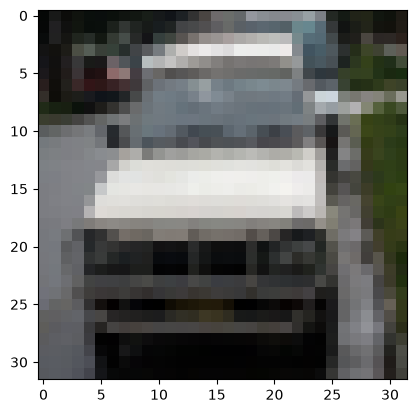

In [69]:
n = 890
plt.imshow(x_test[n])
print("Preditcted: ",labels[np.argmax(predicted_value[n])])
print("Actual: ", labels[np.argmax(y_test[n])])